# HD 155915 (HIP 84642): binary-star fit

NIC2 coronagraphic F160W, 2005-03-15. HD 155915 B lies behind the hole: 220 ± 14 mas at PA 191.3 ± 0.8° with
ΔKs = 2.5 (contrast ≈ 0.10), VLT/NACO 2007-06-05 (Chauvin et al. 2010, Table 6). That is ~1.6 λ/D at F160W, inside
the 0.3″ hole, so the companion is only seen through the hole-edge light.

Model: as `turboklip.ipynb` (wavefront PCA, calibrator optical parameters, 64×64 crop), with the single star replaced
by a binary. Stage 1 fits the star and instrument with the companion fixed at the literature prior; stage 2, from the
stage-1 result, also frees the companion's offset, contrast and spectral shape.

In [1]:
import sys
sys.path.insert(0, '..')

In [2]:
# Basic imports
import jax.numpy as np
import jax.random as jr
import jax.scipy as jsp
import jax
import numpy

jax.config.update("jax_enable_x64", True)

# Optimisation imports
import zodiax as zdx
import optax
import optimistix as optx

# dLux imports
import dLux as dl
import dLux.utils as dlu

# Visualisation imports
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib

%matplotlib inline
plt.rcParams['image.cmap'] = 'inferno'
plt.rcParams["font.family"] = "serif"
plt.rcParams["image.origin"] = 'lower'
plt.rcParams['figure.dpi'] = 72
plt.rcParams["font.size"] = 24

from detectors import *
from apertures import *
from models import *
from stats import posterior
from fitting import *
from plotting import *
from spectra import *

## Binary-star model

`BinaryFit`: the primary at the origin plus a point-source companion through the same optics. Unlike
`hr8799-planets`' stop-gradient planets, the companion's PSF passes gradients to the wavefront and instrument, since a
~10% companion is not negligible.

- `companion_offset`: sky offset of B from A (east, north; arcsec)
- `companion_contrast`: B/A ratio of in-filter detected flux (`CombinedSpectrum.flux`; the spectrum weights are
  normalised internally, so this is exactly the flux ratio)
- `companion_spectrum`: B's spectral shape, the basis weights after the first, which is fixed at 1 (B's overall scale is
  set by the contrast, so a free first weight would be degenerate with it)

All three are keyed by target, so every exposure of the system shares them.

In [3]:
def sky_to_optics(offset, orient):
    """Sky offset (east, north; arcsec) -> optics-frame source position (rad) for an exposure at ORIENTAT `orient` (deg):
    x = -east, y = north, rotated by -ORIENTAT (as hr8799-planets, whose fit recovers the HR 8799 b/c positions;
    a render check against this exposure's WCS matched 1-1.5" offsets in three directions to < 0.1 px)."""
    roll = -np.deg2rad(orient)
    rot = np.array([[np.cos(roll), -np.sin(roll)], [np.sin(roll), np.cos(roll)]])
    return dlu.arcsec2rad(rot @ np.array([-offset[0], offset[1]]))


class BinaryFit(SinglePointFit):
    PARAM_KEYS = SinglePointFit.PARAM_KEYS | {"companion_offset": "target", "companion_contrast": "target",
                                              "companion_spectrum": "target"}
    companion: dl.PointSource

    def __init__(self, spectrum_basis, filter, time_series=False):
        super().__init__(spectrum_basis, filter, time_series)
        nwavels, nbasis = spectrum_basis.shape
        wv, inten = calc_throughput(filter, nwavels)
        self.companion = dl.PointSource(spectrum=CombinedBasisSpectrum(wv, inten, np.zeros(nbasis), spectrum_basis))

    def update_source(self, model, exposure):
        star = super().update_source(model, exposure)
        shape = model.get(self.map_param(exposure, "companion_spectrum"))
        spectrum = self.companion.spectrum.set("basis_weights", np.concatenate([np.ones(1), shape]))
        flux = model.get(self.map_param(exposure, "companion_contrast")) * star.flux
        position = sky_to_optics(model.get(self.map_param(exposure, "companion_offset")), exposure.orient)
        companion = self.companion.set(["spectrum", "flux", "position"], [spectrum, flux, position])
        return dl.Scene([("star", star), ("companion", companion)])


# turboklip's keys (PCA coefficients per visit, as primary_opd in calibrator-joint)
class WavefrontPCABinaryFit(BinaryFit):
    PARAM_KEYS = BinaryFit.PARAM_KEYS | {"cold_mask_shift": "exposure", "cold_mask_tilt": "exposure",
                                         "primary_wpca": "visit", "cold_mask_opd": "exposure", "defocus3": "exposure"}

In [4]:
wid = 64
oversample = 4
pad = 2      # as calibrator-joint: 2 extra detector pixels each side, cropped after resampling

nwavels = 200
npoly = 8

wpca_file = "../data/wavefront_pca.npz"
wpca = np.load(wpca_file)
n_wpca = wpca["modes"].shape[0]
n_modes = int(round(wpca["mean"].size**0.5))   # the fits' Fourier grid
n_zernikes = 50                                 # as calibrator-joint; the PCA removed this span (calibrator-pca)

optics = NICMOSFresnelCoronagraph(512, wid, oversample, n_modes=n_modes, n_zernikes=n_zernikes, n_nodes=20,
                                  wavefront_pca=wpca_file, pad=pad)
detector = NICMOSDetector(oversample, wid, pad=pad)

vects = np.load(f"../data/iterative_spectrum_basis_F160W_{nwavels}.npy")[:, :npoly]
assert vects.shape == (nwavels, npoly)
spectrum_basis = vects/np.sqrt(np.mean(vects**2, axis=0))

ddir = '../data/NICMOS-LAPL-DD2/LAPL_DATA_DD2/comtemp_flats-DD2/'

# One exposure at one roll to start. The visit: roll 35.3 deg = n918b1e5q, e6q, e7q (192 s), e8q (288 s);
# roll 65.2 deg = n918b2ebq, ecq, edq (192 s), eeq (288 s)
exposures_single = [
    exposure_from_file(ddir + f'{root}_o_clc_calf.fits', WavefrontPCABinaryFit(spectrum_basis, "F160W"),
                       crop=wid, extra_bad=None, hole_margin=0.1)
    for root in ["n918b1e5q"]
]
for exp in exposures_single:
    print(exp.key, exp.target, f"ORIENTAT {exp.orient:.1f}", f"{exp.exptime:.0f} s")

n918b1e5q HIP84642 ORIENTAT 35.3 192 s


In [5]:
# Literature prior for B relative to A (Chauvin et al. 2010, Table 6; VLT/NACO Ks, 2007-06-05). Orbital motion between
# that epoch and 2005-03-15 is unknown, so this is only a starting point
sep, pa, dmag = 0.220, 191.3, 2.5     # arcsec, deg (east of north), Ks
companion_offset = np.array([sep*np.sin(np.deg2rad(pa)), sep*np.cos(np.deg2rad(pa))])   # (east, north)
companion_contrast = 10**(-0.4*dmag)
print("companion offset (east, north) =", companion_offset, "arcsec; contrast =", float(companion_contrast))

optical_params = np.load("../data/calibrator_optical_params.npy", allow_pickle=True)[()]
per_exposure_init = ["cold_mask_shift", "cold_mask_opd", "defocus1", "defocus2"]   # medians as starting values

params = {k: {} for k in ["spectrum", "primary_wpca", "primary_low", "primary_tilt", "cold_mask_tilt", "bias",
                          "companion_offset", "companion_contrast", "companion_spectrum"] + per_exposure_init}
for exp in exposures_single:
    key = lambda k: exp.fit.get_key(exp, k)
    params["spectrum"][key("spectrum")] = np.zeros(npoly).at[0].set(1.)          # rescaled below
    params["primary_tilt"][key("primary_tilt")] = np.array([-0.05, -0.75])*0.075
    params["cold_mask_tilt"][key("cold_mask_tilt")] = hole_tilt(exp)             # as calibrator-joint
    params["primary_wpca"][key("primary_wpca")] = np.zeros(n_wpca)               # 0 = the calibrators' mean wavefront
    params["primary_low"][key("primary_low")] = np.zeros(n_zernikes)
    params["bias"][key("bias")] = 0.
    params["companion_offset"][key("companion_offset")] = companion_offset
    params["companion_contrast"][key("companion_contrast")] = np.asarray(companion_contrast)
    params["companion_spectrum"][key("companion_spectrum")] = np.zeros(npoly - 1)   # basis vector 0 only; reset to A's fitted shape before stage 2
    for k in per_exposure_init:
        params[k][key(k)] = np.asarray(optical_params[k]["global"])

params |= {k: v for k, v in optical_params.items() if k not in per_exposure_init}

model_single = set_array(NICMOSModel(exposures_single, params, optics, detector))
params = ModelParams(params)

# Star flux: match the total flux of the data over the unmasked pixels (as turboklip). The companion's flux is
# contrast x the star's, so it scales with it
render = eqx.filter_jit(lambda m, e: e.fit(m, e))
im = [render(params.inject(model_single), e) for e in exposures_single]
c = sum(np.nansum(np.where(e.bad, 0., e.data)) for e in exposures_single) / sum(np.nansum(np.where(e.bad, 0., s)) for e, s in zip(exposures_single, im))
params = ModelParams(params.params | {"spectrum": jax.tree.map(lambda s: s*c, params.params["spectrum"])})

companion offset (east, north) = [-0.04310815 -0.21573522] arcsec; contrast = 0.1


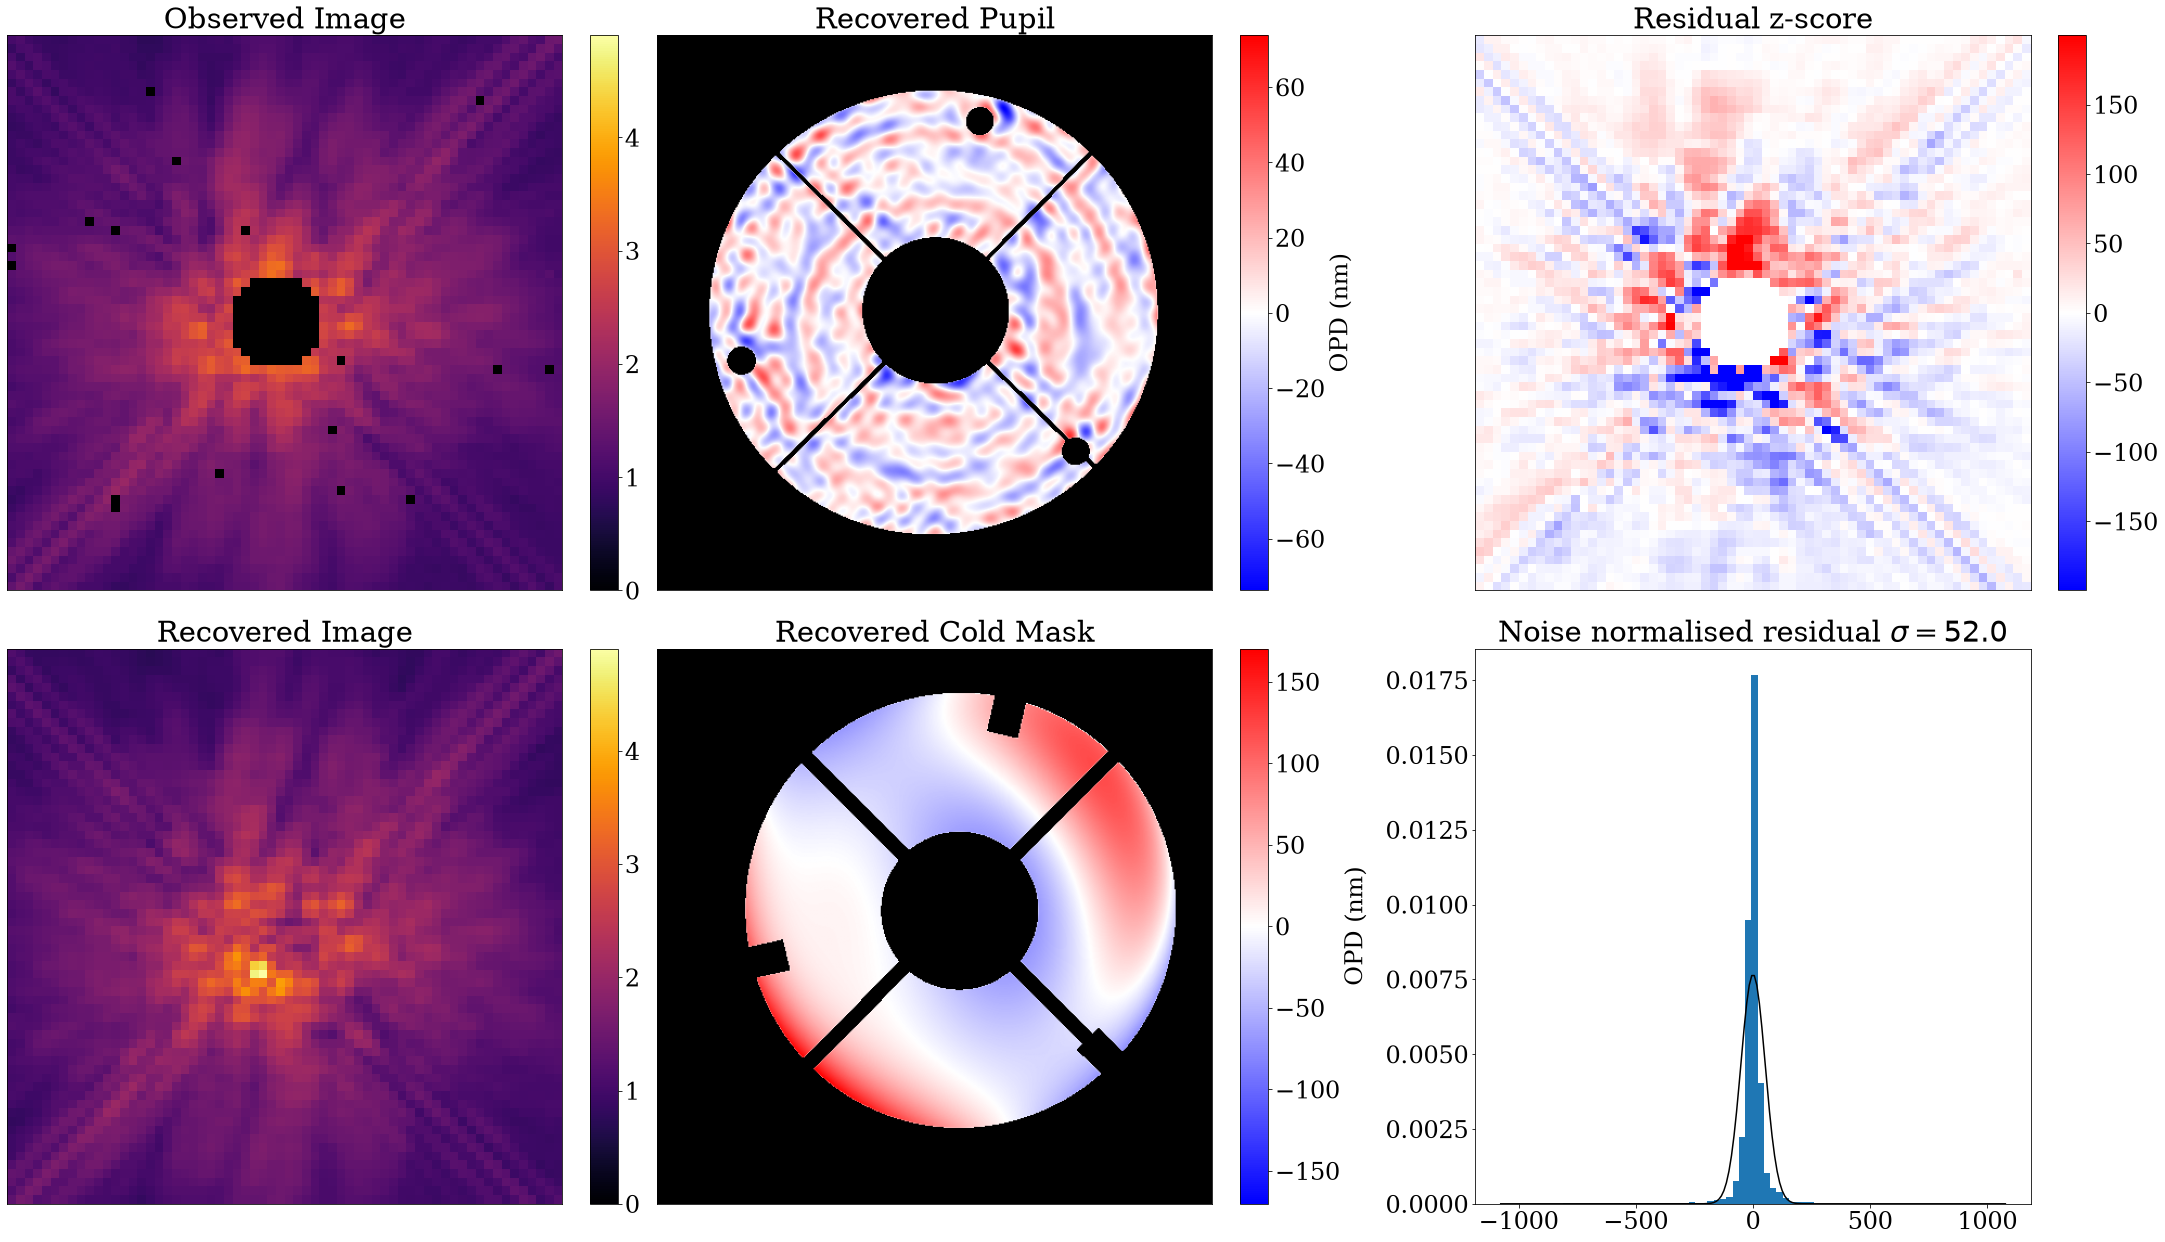

In [6]:
plot_comparison(model_single, params, exposures_single, percentile=99, wf_size=512)

## Stage 1: star and instrument, companion fixed at the prior

In [ ]:
g = 5e-2
things_start = {
    "spectrum": sgd(g*3, 30.),
    "primary_tilt": sgd(g*5, 15.),
    "cold_mask_tilt": sgd(g*1, 0),
    "cold_mask_opd": sgd(g*0.1, 40),
    "defocus1": sgd(g*1, 60),
    "defocus2": sgd(g*10, 60),
    "bias": sgd(g*3, 50),
    "cold_mask_shift": sgd(g*0.3, 70),
    "primary_low": sgd(g*2., 150),
    "primary_wpca": sgd(g*5, 100),
    # global optical state fixed at the calibrator medians; companion_* fixed at the prior until stage 2
}

opt_params = set_array({k: v for k, v in params.params.items() if k in things_start})
losses, params_history = optimise_new(
    opt_params, model_single, exposures_single, things_start, 300,
    precond_method="gn_probe", precond_kwargs=dict(n_probes=32, chunk=2, per_block=True))

In [ ]:
plt.figure(figsize=(10, 6)); plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.title("stage 1")
plot_params(params_history, list(things_start.keys()), xw=3)
plot_comparison_detailed(model_single, ModelParams(params_history[-1]), exposures_single, quadrature=False, wf_size=512, percentile=99)

## Stage 2: also free the companion

From the stage-1 result. The stage-1 parameters keep their learning rates with no delay; the companion parameters
start after a short delay so the (recomputed) preconditioner and the rest of the model settle first. Check the stage-1
loss has flattened before running this.

**Caveat:** with `hole_margin=0.1` everything inside 0.4″ is masked, and B (0.22″) is also inside the 0.3″ hole, so B is constrained only by its attenuated wings beyond 0.4″, which resemble the speckles the wavefront terms fit. Treat the fitted offset/contrast as a measurement only after checking the loss has a real minimum in them (a scan over contrast and offset, or their Fisher curvature), and ideally after adding the 65.2° roll, where B rotates with the sky and static speckles do not. `companion_spectrum` (7 shape terms from one broadband image) is weakly constrained; freeze it if it wanders.

In [ ]:
stage1 = params.params | params_history[-1]
# B starts from A's fitted spectral shape (A's coefficients over its first one); its flux is set by the contrast
stage1["companion_spectrum"] = {k: stage1["spectrum"][k][1:]/stage1["spectrum"][k][0] for k in stage1["companion_spectrum"]}

things = {k: sgd(g*lr, 0) for k, lr in {"spectrum": 3, "primary_tilt": 5, "cold_mask_tilt": 1, "cold_mask_opd": 0.1,
                                        "defocus1": 1, "defocus2": 10, "bias": 3, "cold_mask_shift": 0.3,
                                        "primary_low": 2, "primary_wpca": 5}.items()}
things |= {
    "companion_offset": sgd(g*0.3, 20),
    "companion_contrast": sgd(g*1, 20),
    "companion_spectrum": sgd(g*0.3, 50),
}

model_single = ModelParams(stage1).inject(model_single)
opt_params = set_array({k: v for k, v in stage1.items() if k in things})
losses2, params_history2 = optimise_new(
    opt_params, model_single, exposures_single, things, 300,
    precond_method="gn_probe", precond_kwargs=dict(n_probes=32, chunk=4, per_block=True))

In [ ]:
plt.figure(figsize=(10, 6)); plt.plot(losses2); plt.xlabel("step"); plt.ylabel("loss"); plt.title("stage 2")
plot_params(params_history2, list(things.keys()), xw=3)
final = ModelParams(stage1 | params_history2[-1])
plot_comparison_detailed(model_single, final, exposures_single, quadrature=False, wf_size=512, percentile=99)

In [ ]:
# Fitted companion vs the literature prior
exp = exposures_single[0]
east, north = numpy.asarray(final.get(exp.fit.map_param(exp, "companion_offset")))
contrast = float(final.get(exp.fit.map_param(exp, "companion_contrast")))
print(f"B: sep {numpy.hypot(east, north)*1e3:.1f} mas, PA {numpy.rad2deg(numpy.arctan2(east, north)) % 360:.1f} deg, "
      f"contrast {contrast:.4f} (dF160W {-2.5*numpy.log10(contrast):.2f} mag; not directly comparable to dKs)")
print(f"prior (NACO Ks 2007): sep {sep*1e3:.0f} +/- 14 mas, PA {pa:.1f} +/- 0.8 deg, contrast {float(companion_contrast):.4f} (dKs {dmag} +/- 0.1)")